# 线性回归模型与诊断
数据说明：本数据是一份汽车贷款数据
 
假定：
  - "creditcard_exp.csv"保存了上一期的数据，Acc、avg_exp和avg_exp为观察期的因变量取值，剩余字段为分析窗口（观察期之前）的自变量取值
  - "creditcard_exp_out_of_sample.csv"保存了本期分析窗口内的自变量，其因变量需要通过模型输出

|字段名|中文含义|
|:--:|:--:|
|id|id|
|Acc|是否开卡(1=已开通)|
|avg_exp|月均信用卡支出（元）|
|avg_exp_ln|月均信用卡支出的自然对数|
|gender|性别(男=1)|
|Age|年龄|
|Income|年收入（万元）|
|Ownrent|是否自有住房（有=1；无=0)|
|Selfempl|是否自谋职业(1=yes, 0=no)|
|dist_home_val|所住小区房屋均价(万元)|
|dist_avg_income|当地人均收入|
|high_avg|高出当地平均收入|
|edu_class|教育等级：小学及以下开通=0，中学=1，本科=2，研究生=3|

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols

pd.set_option('display.max_columns', 8)

#### 导入数据和数据清洗

In [2]:
raw_data = pd.read_csv('creditcard_exp.csv', skipinitialspace=True)
out_of_sample_data = pd.read_csv('creditcard_exp_out_of_sample.csv', skipinitialspace=True)
raw_data.head()

,id,Acc,avg_exp,avg_exp_ln,...,dist_avg_income,age2,high_avg,edu_class
0,19,1,1217.03,7.104169,...,15.932789,1600,0.102361,3
1,5,1,1251.50,7.132098,...,15.796316,1024,0.051184,2
2,95,0,NaN,NaN,...,7.490000,1296,0.910000,1
3,86,1,856.57,6.752936,...,11.275632,1681,0.197218,3
4,50,1,1321.83,7.186772,...,13.346474,784,0.062676,2


In [5]:
train = raw_data[raw_data['avg_exp'].notnull()].copy().iloc[:, 2:]\
    .drop('age2',axis=1)

oos_data = out_of_sample_data.copy()\
    .drop('age2',axis=1)

train.describe(include='all')

,avg_exp,avg_exp_ln,gender,Age,...,dist_home_val,dist_avg_income,high_avg,edu_class
count,70.000000,70.000000,70.000000,70.000000,...,70.000000,70.000000,70.000000,70.000000
mean,983.655429,6.787787,0.285714,31.157143,...,74.540857,8.005472,-0.580766,1.928571
std,446.294237,0.476035,0.455016,7.206349,...,36.949228,3.070744,0.432808,0.873464
min,163.180000,5.094854,0.000000,20.000000,...,13.130000,3.828842,-1.526850,0.000000
25%,697.155000,6.547003,0.000000,26.000000,...,49.302500,5.915553,-0.887981,1.000000
50%,884.150000,6.784627,0.000000,30.000000,...,65.660000,7.084184,-0.612068,2.000000
75%,1229.585000,7.114415,1.000000,36.000000,...,105.067500,9.123105,-0.302082,3.000000
max,2430.030000,7.795659,1.000000,55.000000,...,157.900000,18.427000,0.259337,3.000000


#### 相关性分析
散点图

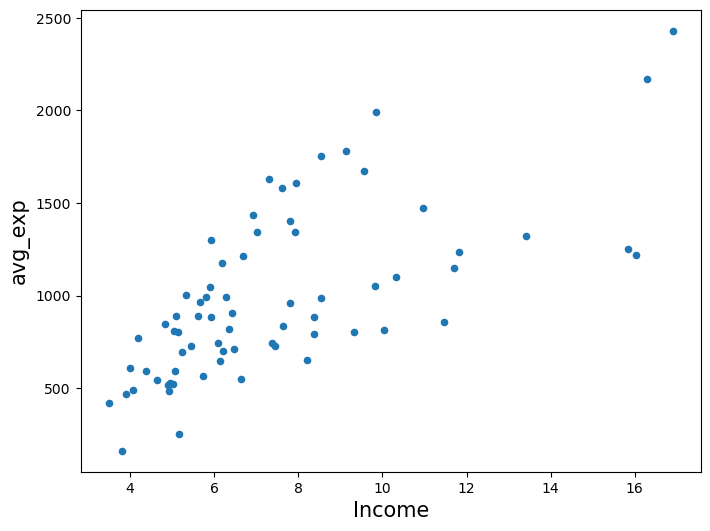

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_ylabel(..., fontsize=15)
ax.set_xlabel(..., fontsize=15)
train.plot('Income', 'avg_exp', kind='scatter', ax=ax)
plt.show()

In [7]:
train[['Income', 'avg_exp', 'Age', 'dist_home_val']].corr(method='pearson')

,Income,avg_exp,Age,dist_home_val
Income,1.000000,0.674011,0.369129,0.249153
avg_exp,0.674011,1.000000,0.258478,0.319499
Age,0.369129,0.258478,1.000000,0.109323
dist_home_val,0.249153,0.319499,0.109323,1.000000


## 1、线性回归算法
### 简单线性回归

In [8]:
simple_linear_model = ols(formula='avg_exp ~ Income', data=train).fit()
print(simple_linear_model.params)

Intercept    258.049498
Income        97.728578
dtype: float64


In [9]:
summary = simple_linear_model.summary()
for table in summary.tables:
    print(table)

                            OLS Regression Results                            
Dep. Variable:                avg_exp   R-squared:                       0.454
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     56.61
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.60e-10
Time:                        08:21:48   Log-Likelihood:                -504.69
No. Observations:                  70   AIC:                             1013.
Df Residuals:                      68   BIC:                             1018.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    258.0495    104.290      2.474      0.0

In [10]:
simple_linear_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                avg_exp   R-squared:                       0.454
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     56.61
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.60e-10
Time:                        08:21:48   Log-Likelihood:                -504.69
No. Observations:                  70   AIC:                             1013.
Df Residuals:                      68   BIC:                             1018.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    258.0495    104.290      2.474      0.016      49.942     466.157
Income        97.7286     12.989      7.524      0.000      71.809     123.648
==============================================================================
Omnibus:                        3.714   Durbin-Watson:                   1.424
Prob(Omnibus):                  0.156   Jarque-Bera (JB):                3.507
Skew:                           0.485   Prob(JB):                        0.173
Kurtosis:                       2.490   Cond. No.                         21.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Predict-在原始数据集上得到预测值和残差

In [11]:
train_prediction = simple_linear_model.predict(train)
train_resid = simple_linear_model.resid
pd.DataFrame(
    [train_prediction, train_resid], 
    index=['Pred_avg_exp', 'resid']
).T.head()

,Pred_avg_exp,resid
0,1825.141904,-608.111904
1,1806.803136,-555.303136
3,1379.274813,-522.704813
4,1568.506658,-246.676658
5,1238.281793,-422.251793


在待预测数据集上得到预测值

In [12]:
print(simple_linear_model.predict(oos_data)[:5])

0    982.218260
1    749.624245
2    649.941095
3    631.372665
4    661.668525
dtype: float64


### 多元线性回归

In [13]:
multiple_linear_model = ols(
    'avg_exp ~Income + dist_home_val + dist_avg_income',
    data=train).fit()
multiple_linear_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                avg_exp   R-squared:                       0.541
Model:                            OLS   Adj. R-squared:                  0.520
Method:                 Least Squares   F-statistic:                     25.95
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           3.34e-11
Time:                        08:21:49   Log-Likelihood:                -498.62
No. Observations:                  70   AIC:                             1005.
Df Residuals:                      66   BIC:                             1014.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           2.3507    122.525      0.019      0.985    -242.278     246.980
Income           -164.4378     86.487     -1.901      0.062    -337.115       8.239
dist_home_val       1.5396      1.049      1.468      0.147      -0.555       3.634
dist_avg_income   260.7522     87.058      2.995      0.004      86.934     434.570
==============================================================================
Omnibus:                        5.379   Durbin-Watson:                   1.593
Prob(Omnibus):                  0.068   Jarque-Bera (JB):                5.367
Skew:                           0.642   Prob(JB):                       0.0683
Kurtosis:                       2.563   Cond. No.                         325.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
print(multiple_linear_model.params)

Intercept            2.350664
Income            -164.437844
dist_home_val        1.539601
dist_avg_income    260.752162
dtype: float64


# 2、多元线性回归的变量筛选

In [15]:
'''forward select'''
def forward_select(data, response):
    remaining = set(data.columns)
    remaining.remove(response)
    selected = []
    current_score, best_new_score = float('inf'), float('inf')
    while remaining:
        aic_with_candidates=[]
        for candidate in remaining:
            formula = "{} ~ {}".format(
                response,' + '.join(selected + [candidate]))
            aic = ols(formula=formula, data=data).fit().aic
            aic_with_candidates.append((aic, candidate))
        aic_with_candidates.sort(reverse=True)
        best_new_score, best_candidate=aic_with_candidates.pop()
        if current_score > best_new_score: 
            remaining.remove(best_candidate)
            selected.append(best_candidate)
            current_score = best_new_score
            print ('aic is {},continuing!'.format(current_score))
        else:        
            print ('forward selection over!')
            break
            
    formula = "{} ~ {} ".format(response,' + '.join(selected))
    print('final formula is {}'.format(formula))
    model = ols(formula=formula, data=data).fit()
    return(model)

In [16]:
data_for_select = train[['avg_exp', 'Income', 'Age', 'dist_home_val', 
                         'dist_avg_income']]
forward_select_model = forward_select(data=data_for_select, response='avg_exp')
print(forward_select_model.rsquared)

aic is 1007.6801413968115,continuing!
aic is 1005.4969816306302,continuing!
aic is 1005.2487355956046,continuing!
forward selection over!
final formula is avg_exp ~ dist_avg_income + Income + dist_home_val 
0.5411512928411949


# 3、线性回归的诊断
### 残差分析

In [17]:
def plot_resid(resid, x, y_hat, **kw):
    plt.figure(figsize=(8, 8))
    
    # “残差-X”散点图
    ax1 = plt.subplot(211)
    ax1.set_ylabel('resid', fontsize=15)
    ax1.set_xlabel('x', fontsize=15)
    ax1.scatter(x, resid, **kw)
    ax1.set_title('Scatter of resid - x', fontsize=15)
    
    # "残差-Y估计”散点图
    ax2 = plt.subplot(212)
    ax2.set_ylabel('resid', fontsize=15)
    ax2.set_xlabel('y_hat', fontsize=15)
    ax2.scatter(y_hat, resid, **kw)
    ax2.set_title('Scatter of resid - y_hat', fontsize=15)
    
    # 输出图形
    plt.tight_layout() 
    plt.show()

In [18]:
train['Income_ln'] = np.log(train['Income'])

# 样本外数据做同样变换
oos_data['Income_ln'] = np.log(oos_data['Income'])  

# 对x和y各自取对数，比较结果
linear_model1 = ols(formula='avg_exp ~ Income', data=train).fit()
linear_model2 = ols(formula='avg_exp_ln ~ Income', data=train).fit()
linear_model3 = ols(formula='avg_exp_ln ~ Income_ln', data=train).fit()

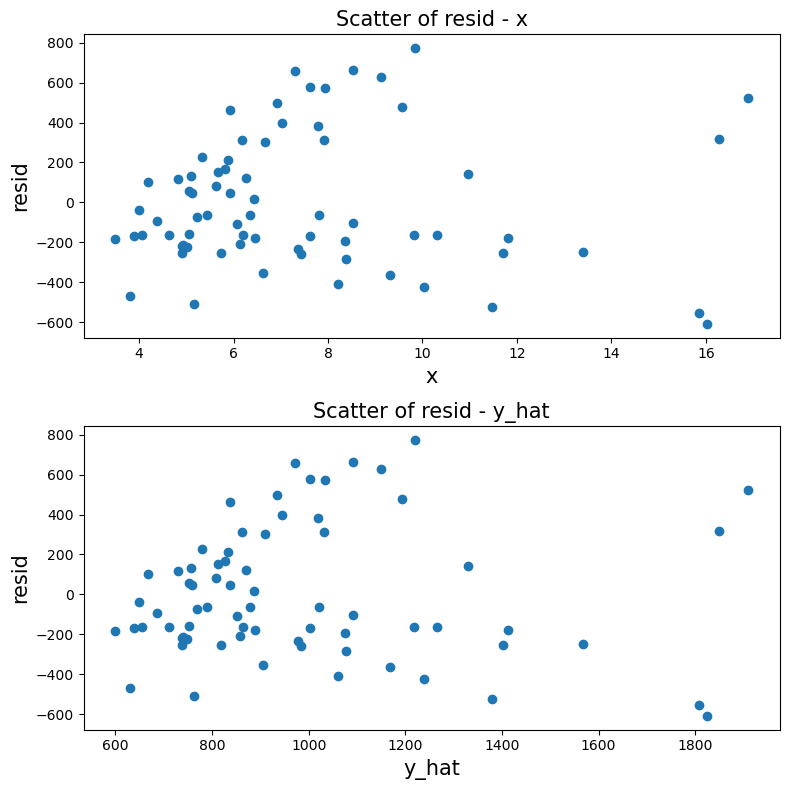

In [19]:
plot_resid(linear_model1.resid, 
           train['Income'],
           linear_model1.predict(train))

遇到异方差情况,教科书上会介绍使用加权最小二乘法，但是实际上最常用的是对被解释变量取对数

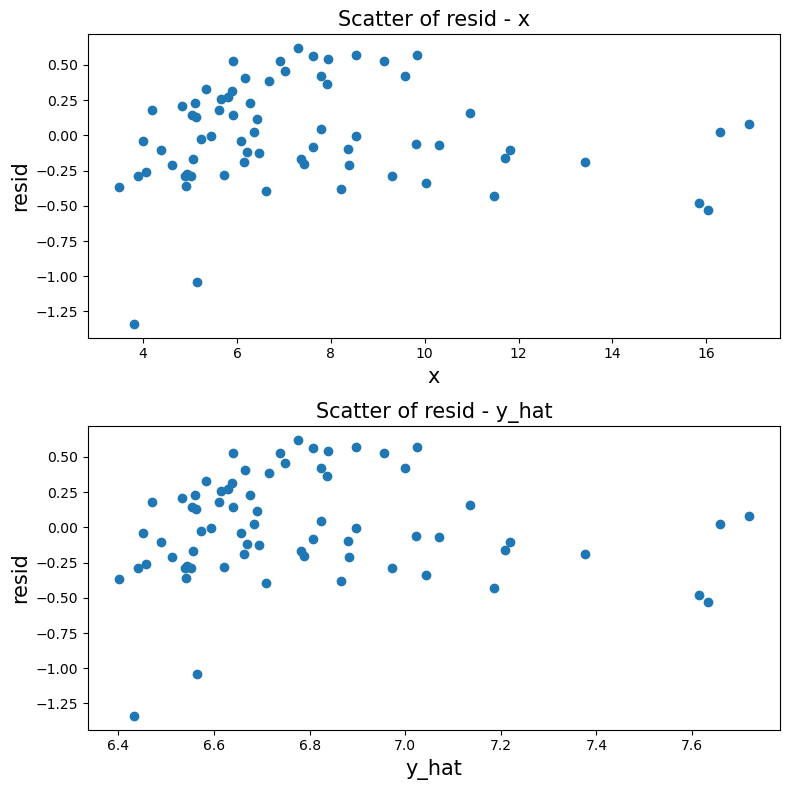

In [20]:
plot_resid(linear_model2.resid, 
           train['Income'],
           linear_model2.predict(train))

取对数会使模型更有解释意义

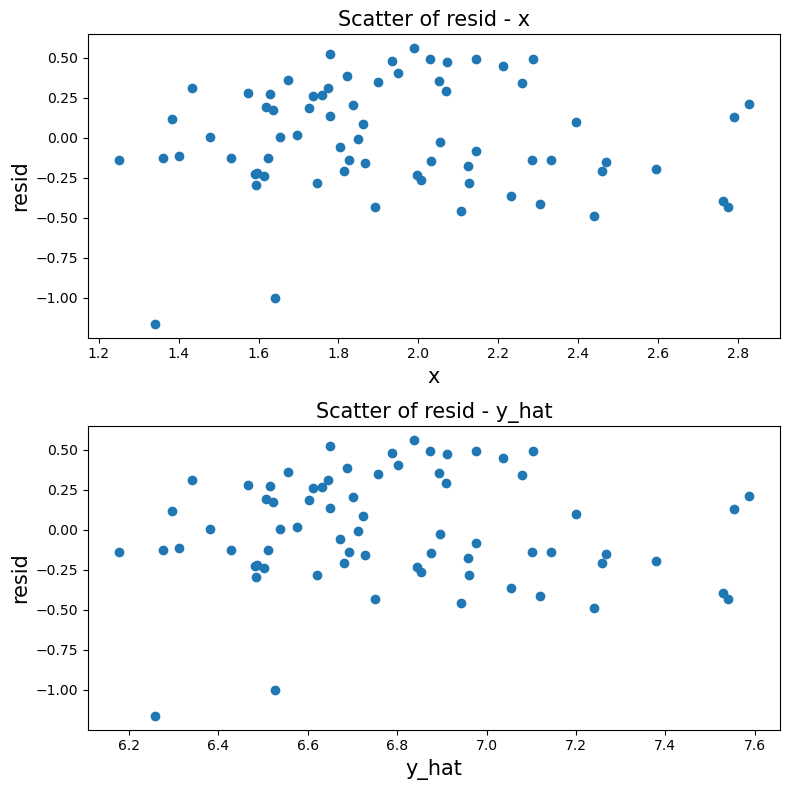

In [21]:
plot_resid(linear_model3.resid, 
           train['Income_ln'],
           linear_model3.predict(train))

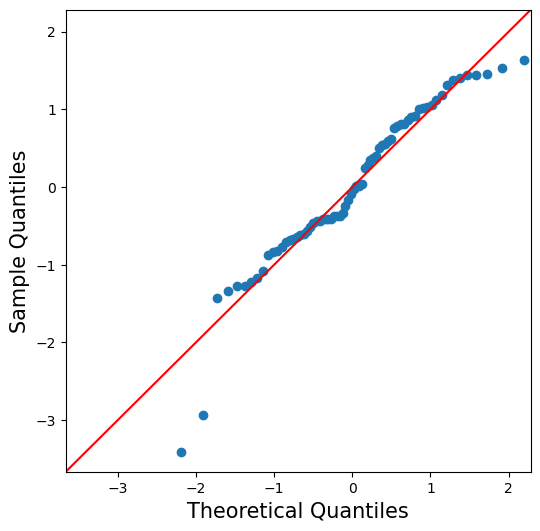

In [22]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlabel(..., fontsize=15)
ax.set_ylabel(..., fontsize=15)
sm.qqplot(linear_model3.resid, fit=True, line='45', ax=ax, figure=fig)
plt.show()

寻找最优的模型

In [23]:
import pprint

r_squares = {'exp ~ Income':  linear_model1.rsquared, 
             'ln(exp) ~ Income': linear_model2.rsquared, 
             'ln(exp) ~ ln(Income)': linear_model3.rsquared}
pprint.pprint(r_squares)

{'exp ~ Income': 0.45429062315565294,
 'ln(exp) ~ Income': 0.403085555532965,
 'ln(exp) ~ ln(Income)': 0.4803927993893108}


### 强影响点分析

In [24]:
train['resid'] = linear_model3.resid
student_resid = (train['resid'] - train['resid'].mean()
                   ) / train['resid'].std()

Find outlier：

In [25]:
train[np.abs(student_resid) > 2]

,avg_exp,avg_exp_ln,gender,Age,...,high_avg,edu_class,Income_ln,resid
73,251.56,5.527682,0,29,...,-0.335147,0,1.640510,-0.998649
98,163.18,5.094854,0,22,...,-0.181889,0,1.339177,-1.162337


statemodels包提供了更多强影响点判断指标

In [26]:
from statsmodels.stats.outliers_influence import OLSInfluence

OLSInfluence(linear_model3).summary_frame().head()

,dfb_Intercept,dfb_Income_ln,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
0,0.343729,-0.381393,0.085587,-1.319633,0.089498,-0.413732,-1.326996,-0.416040
1,0.307196,-0.341294,0.069157,-1.201699,0.087409,-0.371907,-1.205702,-0.373146
3,0.207619,-0.244956,0.044984,-1.440468,0.041557,-0.299947,-1.452165,-0.302382
4,0.112301,-0.127713,0.010759,-0.575913,0.060926,-0.146693,-0.573062,-0.145967
5,0.120572,-0.150924,0.022274,-1.221080,0.029011,-0.211064,-1.225579,-0.211842


Drop outlier

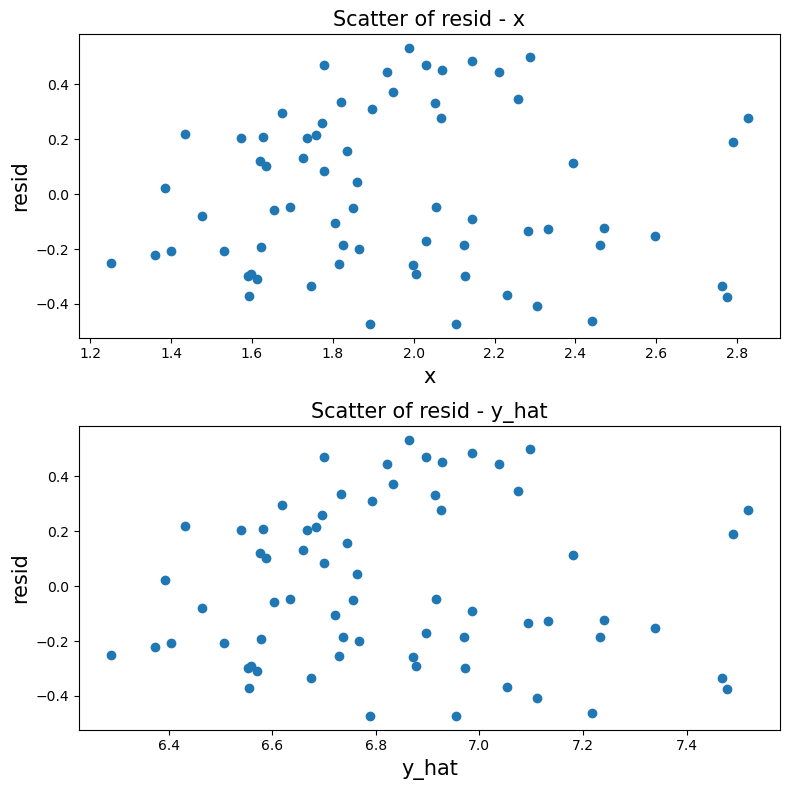

In [27]:
train = train[np.abs(student_resid) <= 2].copy()
linear_model4 = ols('avg_exp_ln ~ Income_ln', train).fit()

plot_resid(linear_model4.resid, 
           train['Income_ln'],
           linear_model4.predict(train))

In [28]:
linear_model4.rsquared

0.49397191385172456

### 多重共线性分析

In [29]:
# Step regression is not always work.


经过单变量线性回归的处理，我们基本对模型的性质有了一定的了解，接下来可以放入更多的连续型解释变量。在加入变量之前，要注意变量的函数形式转变。比如当地房屋均价、当地平均收入，其性质和个人收入一样，都需要取对数

In [30]:
# 对解释变量取对数
train['dist_home_val_ln'] = np.log(train['dist_home_val'])
train['dist_avg_income_ln'] = np.log(train['dist_avg_income'])

# 对本期数据也做同样变换
oos_data['dist_home_val_ln'] = np.log(oos_data['dist_home_val'])
oos_data['dist_avg_income_ln'] = np.log(oos_data['dist_avg_income'])

linear_model5 = ols('''avg_exp_ln ~ Age + Income_ln + 
           dist_home_val_ln + dist_avg_income_ln''', train).fit()
linear_model5.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             avg_exp_ln   R-squared:                       0.553
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     19.48
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.79e-10
Time:                        08:21:59   Log-Likelihood:                -7.3496
No. Observations:                  68   AIC:                             24.70
Df Residuals:                      63   BIC:                             35.80
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              4.6265      0.317     14.574      0.000       3.992       5.261
Age                   -0.0006      0.005     -0.117      0.907      -0.011       0.010
Income_ln             -0.1802      0.569     -0.317      0.752      -1.317       0.957
dist_home_val_ln       0.1258      0.058      2.160      0.035       0.009       0.242
dist_avg_income_ln     1.0093      0.612      1.649      0.104      -0.214       2.233
==============================================================================
Omnibus:                        4.111   Durbin-Watson:                   1.609
Prob(Omnibus):                  0.128   Jarque-Bera (JB):                2.466
Skew:                           0.248   Prob(JB):                        0.291
Kurtosis:                       2.210   Cond. No.                         807.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The function "statsmodels.stats.outliers_influence.variance_inflation_factor" uses "OLS" to fit data, and it will generates a wrong rsquared. So define it ourselves!

In [31]:
def vif(df, y_col):
    x_cols = list(df.columns)
    x_cols.remove(y_col)
    formula = y_col + '~' + '+'.join(x_cols)
    rsquared = ols(formula, df).fit().rsquared
    return 1. / (1. - rsquared)

exog = train[['Age', 'Income_ln', 'dist_home_val_ln',
             'dist_avg_income_ln']]

for y_col in exog.columns:
    print('VIF of "%s" is %.2f' %(y_col, vif(df=exog, y_col=y_col)))

VIF of "Age" is 1.17
VIF of "Income_ln" is 36.98
VIF of "dist_home_val_ln" is 1.05
VIF of "dist_avg_income_ln" is 36.92


Income_ln与dist_avg_income_ln具有共线性，使用“高出平均收入的比率”代替其中一个

In [32]:
train['high_avg_ratio'] = train['high_avg'] / train['dist_avg_income']
oos_data['high_avg_ratio'] = oos_data['high_avg'] / oos_data['dist_avg_income']

In [33]:
exog = train[['Age', 'high_avg_ratio', 'dist_home_val_ln', 
              'dist_avg_income_ln']]

for y_col in exog.columns:
    print('VIF of "%s" is %.2f' %(y_col, vif(df=exog, y_col=y_col)))

VIF of "Age" is 1.17
VIF of "high_avg_ratio" is 1.13
VIF of "dist_home_val_ln" is 1.05
VIF of "dist_avg_income_ln" is 1.31


In [34]:
var_select_data = train[['avg_exp_ln', 'Age', 'high_avg_ratio', 
                         'dist_home_val_ln', 'dist_avg_income_ln']]
linear_model6 = forward_select(data=var_select_data, 
                               response='avg_exp_ln')
print('r_squared is ', linear_model6.rsquared)

aic is 23.816793700737392,continuing!
aic is 20.830952279560776,continuing!
forward selection over!
final formula is avg_exp_ln ~ dist_avg_income_ln + dist_home_val_ln 
r_squared is  0.5520397736845981


### 增加离散变量

In [35]:
formula = '''
avg_exp_ln ~ dist_avg_income_ln + dist_home_val_ln + 
C(gender) + C(Ownrent) + C(Selfempl) + C(edu_class)
'''
linear_model7 = ols(formula, train).fit()
linear_model7.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             avg_exp_ln   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.858
Method:                 Least Squares   F-statistic:                     58.71
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.75e-24
Time:                        08:22:00   Log-Likelihood:                 35.337
No. Observations:                  68   AIC:                            -54.67
Df Residuals:                      60   BIC:                            -36.92
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              4.5520      0.212     21.471      0.000       4.128       4.976
C(gender)[T.1]        -0.4301      0.060     -7.200      0.000      -0.550      -0.311
C(Ownrent)[T.1]        0.0184      0.045      0.413      0.681      -0.071       0.107
C(Selfempl)[T.1]      -0.3805      0.119     -3.210      0.002      -0.618      -0.143
C(edu_class)[T.2]      0.2895      0.051      5.658      0.000       0.187       0.392
C(edu_class)[T.3]      0.4686      0.060      7.867      0.000       0.349       0.588
dist_avg_income_ln     0.9563      0.098      9.722      0.000       0.760       1.153
dist_home_val_ln       0.0522      0.034      1.518      0.134      -0.017       0.121
==============================================================================
Omnibus:                        3.788   Durbin-Watson:                   2.129
Prob(Omnibus):                  0.150   Jarque-Bera (JB):                4.142
Skew:                           0.020   Prob(JB):                        0.126
Kurtosis:                       4.208   Cond. No.                         60.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [36]:
formula = '''
avg_exp_ln ~ dist_avg_income_ln + dist_home_val_ln + 
C(Selfempl) + C(gender) * C(edu_class) 
'''
linear_model8 = ols(formula, train).fit()
linear_model8.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             avg_exp_ln   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     78.50
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           1.42e-28
Time:                        08:22:01   Log-Likelihood:                 48.743
No. Observations:                  68   AIC:                            -79.49
Df Residuals:                      59   BIC:                            -59.51
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                            4.4098      0.178     24.839      0.000       4.055       4.765
C(Selfempl)[T.1]                    -0.2945      0.101     -2.908      0.005      -0.497      -0.092
C(gender)[T.1]                      -0.0054      0.098     -0.055      0.956      -0.201       0.190
C(edu_class)[T.2]                    0.3164      0.045      7.012      0.000       0.226       0.407
C(edu_class)[T.3]                    0.5576      0.054     10.268      0.000       0.449       0.666
C(gender)[T.1]:C(edu_class)[T.2]    -0.4304      0.111     -3.865      0.000      -0.653      -0.208
C(gender)[T.1]:C(edu_class)[T.3]    -0.5948      0.111     -5.362      0.000      -0.817      -0.373
dist_avg_income_ln                   0.9893      0.078     12.700      0.000       0.833       1.145
dist_home_val_ln                     0.0654      0.029      2.278      0.026       0.008       0.123
==============================================================================
Omnibus:                        5.023   Durbin-Watson:                   1.722
Prob(Omnibus):                  0.081   Jarque-Bera (JB):                5.070
Skew:                          -0.328   Prob(JB):                       0.0793
Kurtosis:                       4.166   Cond. No.                         61.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

保存结果

In [37]:
output_data_dir = './data_processed'
if not os.path.exists(output_data_dir):
    os.mkdir(output_data_dir)
output_data_path = os.path.join(output_data_dir, 
                                'creditcard_exp_linear_regression.csv')

# 训练集中的edu_class的取值包括“1， 2， 3”， 
# 而本期中的edu_class则只有“0， 1”，
# 因此将本期中的edu_class=0 概化为1

oos_data['edu_class'].replace({0: 1}, inplace=True)
oos_data['Pred_avg_exp'] = np.exp(linear_model8.predict(oos_data))
oos_data.to_csv(output_data_path, index=False)

# 4、正则算法
### 岭回归

In [38]:
# 对训练集的x进行标准化
continuous_xcols = ['Income', 'dist_home_val', 'dist_avg_income']
raw = train[continuous_xcols].copy()
train_scale = (raw - raw.mean()) / raw.std()

# 使用训练集均值与方差对测试集进行标准化！
oos_raw = oos_data[continuous_xcols].copy()
oos_scale = (oos_raw - raw.mean()) / raw.std()

# 将训练集的y添加进来
train_scale['avg_exp'] = train['avg_exp']

# 训练
linear_model_ridge = ols(
    'avg_exp ~ Income + dist_home_val + dist_avg_income',
    data=train_scale
).fit_regularized(
    alpha=1,    #  正则化系数的倒数
    L1_wt=0     #  `0`代表使用L2正则，即岭回归
)

# 预测
linear_model_ridge.predict(oos_scale)

0     496.913905
1     365.276341
2     291.268826
3     312.115088
4     214.759970
5     357.360400
6     182.041005
7     318.566253
8     211.599504
9     200.462054
10    215.197576
11    175.634772
12    158.954323
13    119.655971
14    280.017027
15    226.155330
16    154.931135
17    134.205549
18    205.171785
19    202.715702
20    167.928538
21     92.767717
22    223.907071
23    167.705162
24    153.437479
25    209.463804
26    153.339336
27    178.399980
28    126.877431
29    175.850226
dtype: float64

### 正则化系数选择：使用scikit-learn自动调优

In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

#  抽取连续变量
continuous_xcols = ['Age', 'Income', 'dist_home_val', 'dist_avg_income']

# 标准化
scaler = StandardScaler()                           # ①模型初始化
scaler.fit(train[continuous_xcols])                 # ②使用fit训练模型
X = scaler.transform(train[continuous_xcols])       # ③使用transform转换
oos_scale = scaler.transform(
    oos_data[continuous_xcols])
y = train['avg_exp_ln']

# 参数搜索：空间 10^-2 到10^3的对数空间取100个值
alphas = np.logspace(-2, 3, 100, base=10)

# 交叉验证得到MSE最小的正则系数alphas
rcv = RidgeCV(
    alphas=alphas,      # 正则化系数的搜索空间
    cv=3,               # 3折交叉验证
)                                                   # ①初始化模型
rcv.fit(X, y)                                       # ②使用fit训练模型
rcv_predict = rcv.predict(oos_scale)                # ③使用predict预测
print("oos prediction:", np.exp(rcv_predict[:5]))   # 预测值取对数的逆变换

# 打印评估结果
print("coef of linear model:", rcv.coef_)
print('The best alpha is {}'.format(rcv.alpha_))
print('The r-square is {}'.format(rcv.score(X, y))) # Default: rsquared


oos prediction: [933.00772049 790.90351714 745.25074061 791.39742451 744.61967633]
coef of linear model: [0.01976292 0.08437189 0.04416857 0.09555532]
The best alpha is 54.62277217684343
The r-square is 0.4372707597355535


### 正则化系数选择：手动选择

岭迹图

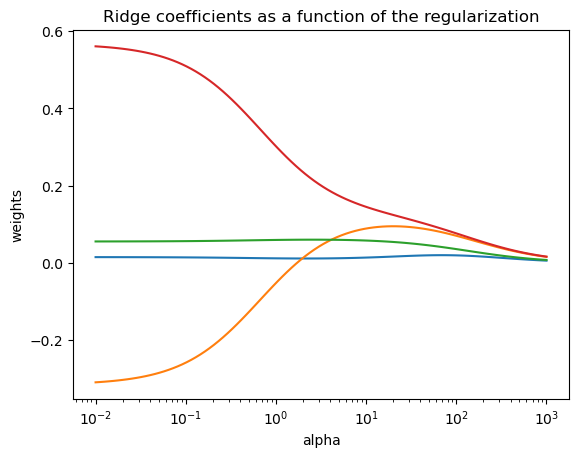

In [40]:
from sklearn.linear_model import Ridge

#  使用不同的正则参数生成一系列岭回归模型
ridge = Ridge()
coefs = []
for alpha in alphas:
    ridge.set_params(alpha=alpha)
    ridge.fit(X, y)
    coefs.append(ridge.coef_)

#  绘制正则参数-回归系数的图形
ax = plt.gca()
ax.plot(alphas, coefs)
ax.set_xscale('log')          # 设置x轴为对数坐标
plt.xlabel('alpha')  
plt.ylabel('weights')
plt.title('Ridge coefficients as a function of the regularization')
plt.axis('tight')
plt.show()

In [41]:
ridge.set_params(alpha=10)
ridge.fit(X, y)

print("Coefs of the model: ", ridge.coef_)
print("The r-square of the model:" , ridge.score(X, y))
print("Prediction of the model: ", np.exp(ridge.predict(oos_scale)[:5]))

Coefs of the model:  [0.01373617 0.08891776 0.05781267 0.14499906]
The r-square of the model: 0.4723921755532807
Prediction of the model:  [924.65780163 761.90724264 706.96758962 744.07923933 670.3623523 ]


### LASSO算法

In [42]:
lmr1 = ols('avg_exp ~ Age + Income + dist_home_val + dist_avg_income',
           data=train).fit_regularized(alpha=1, L1_wt=1)

正则化系数自动选择

In [43]:
from sklearn.linear_model import LassoCV

# 10折交叉验证获取最优正则系数
lasso_alphas = np.logspace(-3, 0, 100, base=10)
lcv = LassoCV(alphas=lasso_alphas, cv=10) # Search the min MSE by CV
lcv.fit(X, y)

print('The best alpha is {}'.format(lcv.alpha_))
print('The r-square is {}'.format(lcv.score(X, y)))  # Default score is rsquared

The best alpha is 0.03274549162877728
The r-square is 0.4721886214149794


正则化参数手动选择

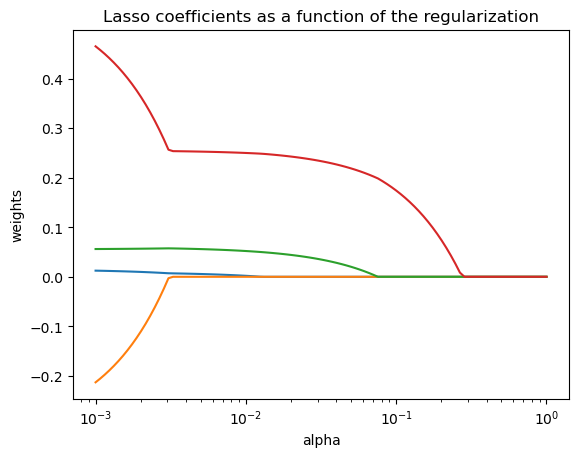

In [44]:
from sklearn.linear_model import Lasso

# 选择不同参数生成lasso回归的系数
lasso = Lasso()
lasso_coefs = []
for alpha in lasso_alphas:
    lasso.set_params(alpha=alpha)
    lasso.fit(X, y)
    lasso_coefs.append(lasso.coef_)

# 绘制lasso正则系数图
ax = plt.gca()
ax.plot(lasso_alphas, lasso_coefs)
ax.set_xscale('log')    # x设为对数坐标
plt.xlabel('alpha')
plt.ylabel('weights')
plt.title('Lasso coefficients as a function of the regularization')
plt.axis('tight')
plt.show()

In [45]:
# 手动设置为0.02
lasso.set_params(alpha=0.02)
lasso.fit(X, y)

print("Coefs of the model: ", lasso.coef_)
print("The best r-square of the model:" , lasso.score(X, y))
print("Prediction of the model: ", np.exp(lasso.predict(oos_scale)[:5]))

Coefs of the model:  [0.         0.         0.04410301 0.24259432]
The best r-square of the model: 0.4787540770624733
Prediction of the model:  [896.67785896 739.94600389 730.00566075 721.9426273  647.98168502]


#### *弹性网络

In [46]:
from sklearn.linear_model import ElasticNetCV

l1_ratio = [0.01, .1, .2, .4, .8, .95, .99, 1]

encv = ElasticNetCV(l1_ratio=l1_ratio, n_alphas=100, n_jobs=-1, cv=4)
encv.fit(X, y)

ElasticNetCV(cv=4, l1_ratio=[0.01, 0.1, 0.2, 0.4, 0.8, 0.95, 0.99, 1],
             n_jobs=-1)

In [47]:
print('The best l1_ratio is {}'.format(encv.l1_ratio_))
print('The best alpha is {}'.format(encv.alpha_))
print('The best r-square of the model is : ', encv.score(X, y))
print('The prediction of the ElasticNet is : ', np.exp(encv.predict(oos_scale)[:5]))

The best l1_ratio is 0.95
The best alpha is 0.10129017757499696
The best r-square of the model is :  0.4039990779384801
The prediction of the ElasticNet is :  [893.91415782 763.4014013  792.8538198  757.64352987 755.00071799]
